In [ ]:
import numpy as np
import os
import pickle
from sklearn.linear_model import LinearRegression
from collections import OrderedDict
import random
import matplotlib.pyplot as plt

In [ ]:
# Download GloVe embeddings if not already present
if not os.path.exists('glove_data/glove.6B.300d.txt'):
    !wget http://nlp.stanford.edu/data/glove.6B.zip
    !unzip glove.6B.zip -d glove_data
    print("GloVe embeddings downloaded")
else:
    print("GloVe embeddings already exist")

GloVe embeddings already exist


In [ ]:
# Download COCO Karpathy splits with pre-extracted VGG features
if not os.path.exists('coco_data'):
    !wget http://www.cs.toronto.edu/~vendrov/order/coco.zip -O coco.zip
    !unzip -q coco.zip -d coco_data
    print("COCO dataset with VGG features downloaded and extracted")
else:
    print("COCO dataset already exists")

# Verify dataset structure
print("\nDataset structure:")
!ls coco_data/data/coco/
print("\nImage features available:")
!ls coco_data/data/coco/images/10crop/

COCO dataset already exists

Dataset structure:
images	test.txt  train.txt  val.txt

Image features available:
test.npy  train.npy  val.npy


In [ ]:
def load_coco_karpathy_splits(base_path):
    """
    Load COCO Karpathy splits with captions and pre-extracted VGG-19 features.
    VGG features are 4096-dimensional fc7 layer outputs.
    """
    def load_captions(filename):
        with open(filename, 'r') as f:
            return [line.strip() for line in f.readlines()]

    # Load captions
    train_caps = load_captions(f"{base_path}/train.txt")
    val_caps = load_captions(f"{base_path}/val.txt")
    test_caps = load_captions(f"{base_path}/test.txt")

    # Load pre-extracted VGG-19 features (4096-dimensional)
    train_im_feats = np.load(f"{base_path}/images/10crop/train.npy")
    val_im_feats = np.load(f"{base_path}/images/10crop/val.npy")
    test_im_feats = np.load(f"{base_path}/images/10crop/test.npy")

    # Verify dimensions
    print(f"Loaded train: {len(train_caps)} captions, {train_im_feats.shape} image features")
    print(f"Loaded val: {len(val_caps)} captions, {val_im_feats.shape} image features")
    print(f"Loaded test: {len(test_caps)} captions, {test_im_feats.shape} image features")
    print(f"VGG feature dimension: {train_im_feats.shape[1]}")

    return (train_caps, train_im_feats), (val_caps, val_im_feats), (test_caps, test_im_feats)

In [ ]:
def load_glove_embeddings(glove_path):
    """Load pretrained GloVe embeddings"""
    embeddings_index = {}
    with open(glove_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            coefs = np.asarray(values[1:], dtype='float32')
            embeddings_index[word] = coefs
    print(f"Loaded {len(embeddings_index)} GloVe word vectors")
    print(f"GloVe dimension: {len(next(iter(embeddings_index.values())))}")
    return embeddings_index

In [ ]:
def compute_glove_features_for_caption(caption, glove_embeddings, dim=300):
    """
    Compute average GloVe features for a single caption.
    As per paper: "we simply average the GloVe vectors relative to the words of the sentence"
    """
    words = caption.lower().split()
    vectors = []
    for word in words:
        if word in glove_embeddings:
            vectors.append(glove_embeddings[word])

    if len(vectors) == 0:
        return np.zeros(dim)
    else:
        return np.mean(vectors, axis=0)

def compute_caption_features(captions, glove_embeddings):
    """Compute GloVe features for all captions"""
    features = []
    for i, caption in enumerate(captions):
        if i % 10000 == 0:
            print(f"Processing caption {i}/{len(captions)}")
        features.append(compute_glove_features_for_caption(caption, glove_embeddings))
    return np.array(features)

In [ ]:
def train_multiresponse_linear_regression(caption_features, image_features):
    """
    Train multi-response linear regression as described in the paper.
    Finds W such that: min ||f_VGG(i) - f_GloVe(c) @ W||²

    Args:
        caption_features: (N, 300) GloVe features
        image_features: (N, 4096) VGG features
    Returns:
        W: (300, 4096) weight matrix
    """
    print(f"Training multi-response regression...")
    print(f"Caption features shape: {caption_features.shape}")
    print(f"Image features shape: {image_features.shape}")

    # Using sklearn's LinearRegression for multi-output regression
    # Fits image_features (target) on caption_features (input)
    regressor = LinearRegression(fit_intercept=False)
    regressor.fit(caption_features, image_features)

    W = regressor.coef_  # W should have shape (300, 4096)
    print(f"Learned weight matrix W shape: {W.shape}")
    return W

def predict_image_features(caption_features, W):
    """Map caption features to image space using learned weights"""
    return caption_features @ W.T  # Add transpose of W


In [ ]:
def compute_similarities(query_features, database_features):
    """
    Compute negative L2 distances (as similarity scores).
    Paper uses S(i,c) = -||f_i(i) - f_c(c)||²
    """
    # Compute L2 distances
    distances = np.linalg.norm(query_features[:, None, :] - database_features[None, :, :], axis=2)
    # Return negative distances as similarities
    return -distances

def evaluate_retrieval(similarities, captions_per_image=5):
    """
    Evaluate image retrieval performance.

    Args:
        similarities: (num_queries, num_images) similarity matrix
        captions_per_image: number of captions per image

    Returns:
        recall_at_1, recall_at_10, mean_rank
    """
    num_queries = similarities.shape[0]
    ranks = []

    for i in range(num_queries):
        # Get sorted indices (highest similarity first)
        sorted_indices = np.argsort(similarities[i])[::-1]

        # Find the true image for this caption
        true_image = i // captions_per_image

        # Find rank of true image (1-indexed)
        rank = np.where(sorted_indices == true_image)[0][0] + 1
        ranks.append(rank)

    ranks = np.array(ranks)

    # Compute metrics
    recall_at_1 = 100.0 * np.mean(ranks == 1)
    recall_at_10 = 100.0 * np.mean(ranks <= 10)
    mean_rank = np.mean(ranks)

    return recall_at_1, recall_at_10, mean_rank

In [ ]:
# Set paths
base_path = 'coco_data/data/coco'
glove_path = 'glove_data/glove.6B.300d.txt'

# Load dataset with VGG features
print("Loading COCO dataset with VGG features...")
(train_caps, train_im_feats), (val_caps, val_im_feats), (test_caps, test_im_feats) = load_coco_karpathy_splits(base_path)
import numpy as np

# Subsample training set
target_num_train_images = 5000
num_train_images = train_im_feats.shape[0]

if num_train_images > target_num_train_images:
    subsample_fraction_train = target_num_train_images / num_train_images

    # Randomly choose which images to keep
    train_indices = np.random.choice(num_train_images, int(num_train_images * subsample_fraction_train), replace=False)

    # Subsample captions (5 captions per image)
    train_caps_subsample = []
    for idx in train_indices:
        train_caps_subsample.extend(train_caps[idx*5:(idx+1)*5])

    # Subsample image features
    train_im_feats_subsample = train_im_feats[train_indices]

    print(f"Subsampled training set: {len(train_im_feats_subsample)} images, {len(train_caps_subsample)} captions")

    # Replace original train sets with subsampled versions
    train_caps = train_caps_subsample
    train_im_feats = train_im_feats_subsample
else:
    print(f"Training set size is small enough ({num_train_images} images), no subsampling applied.")

# Subsample test set
target_num_test_images = 100 # <--- Adjust this number to control test set size
num_test_images = test_im_feats.shape[0]

if num_test_images > target_num_test_images:
    subsample_fraction_test = target_num_test_images / num_test_images

    # Randomly choose which images to keep
    test_indices = np.random.choice(num_test_images, int(num_test_images * subsample_fraction_test), replace=False)

    # Subsample captions (5 captions per image)
    test_caps_subsample = []
    for idx in test_indices:
        test_caps_subsample.extend(test_caps[idx*5:(idx+1)*5])

    # Subsample image features
    test_im_feats_subsample = test_im_feats[test_indices]

    print(f"Subsampled test set: {len(test_im_feats_subsample)} images, {len(test_caps_subsample)} captions")

    # Replace original test sets with subsampled versions
    test_caps = test_caps_subsample
    test_im_feats = test_im_feats_subsample
else:
    print(f"Test set size is small enough ({num_test_images} images), no subsampling applied.")


# Load GloVe embeddings
print("\nLoading GloVe embeddings...")
glove_embeddings = load_glove_embeddings(glove_path)

# Verify data consistency
print(f"\nData consistency check:")
print(f"Training images: {train_im_feats.shape[0]}, captions: {len(train_caps)}")
print(f"Test images: {test_im_feats.shape[0]}, captions: {len(test_caps)}")
print(f"Captions per image (train): {len(train_caps) // train_im_feats.shape[0] if train_im_feats.shape[0] > 0 else 0}")
print(f"Captions per image (test): {len(test_caps) // test_im_feats.shape[0] if test_im_feats.shape[0] > 0 else 0}")

Loading COCO dataset with VGG features...
Loaded train: 566435 captions, (113287, 4096) image features
Loaded val: 25000 captions, (5000, 4096) image features
Loaded test: 25000 captions, (5000, 4096) image features
VGG feature dimension: 4096
Subsampled training set: 5000 images, 25000 captions
Subsampled test set: 100 images, 500 captions

Loading GloVe embeddings...
Loaded 400000 GloVe word vectors
GloVe dimension: 300

Data consistency check:
Training images: 5000, captions: 25000
Test images: 100, captions: 500
Captions per image (train): 5
Captions per image (test): 5


In [ ]:
# For baseline training, we need to properly align caption-image pairs
# Each image has 5 captions, so we need to expand image features

print("Preparing training data for baseline...")

# Expand image features to match captions (5 captions per image)
train_im_feats_expanded = np.repeat(train_im_feats, 5, axis=0)
print(f"Expanded image features shape: {train_im_feats_expanded.shape}")

# Compute caption features
print("\nComputing caption features for training set...")
train_cap_features = compute_caption_features(train_caps, glove_embeddings)
print(f"Caption features shape: {train_cap_features.shape}")

Preparing training data for baseline...
Expanded image features shape: (25000, 4096)

Computing caption features for training set...
Processing caption 0/25000
Processing caption 10000/25000
Processing caption 20000/25000
Caption features shape: (25000, 300)


In [ ]:
# Train the multi-response linear regression model
print("Training baseline multi-response linear regression...")
W_baseline = train_multiresponse_linear_regression(train_cap_features, train_im_feats_expanded)

# Save the model
np.save('baseline_W.npy', W_baseline)
print("Baseline model trained and saved!")

Training baseline multi-response linear regression...
Training multi-response regression...
Caption features shape: (25000, 300)
Image features shape: (25000, 4096)
Learned weight matrix W shape: (4096, 300)
Baseline model trained and saved!


In [ ]:
print("Evaluating Pure Baseline Method...")

# Compute caption features for test set
print("Computing test caption features...")
test_cap_features = compute_caption_features(test_caps, glove_embeddings)

# Load the trained weight matrix
W_baseline = np.load('baseline_W.npy')

# Map test captions to image space
print(f"Shape of test_cap_features: {test_cap_features.shape}")
print(f"Shape of W_baseline: {W_baseline.shape}")
test_cap_mapped = predict_image_features(test_cap_features, W_baseline)

# Compute similarities
similarities_baseline = compute_similarities(test_cap_mapped, test_im_feats)

# Evaluate
recall1_bl, recall10_bl, mean_rank_bl = evaluate_retrieval(similarities_baseline)

print(f"\nBaseline Results (as per Table 1):")
print(f"R@1: {recall1_bl:.1f}%")
print(f"R@10: {recall10_bl:.1f}%")
print(f"Mean r: {mean_rank_bl:.1f}")

Evaluating Pure Baseline Method...
Computing test caption features...
Processing caption 0/500
Shape of test_cap_features: (500, 300)
Shape of W_baseline: (4096, 300)

Baseline Results (as per Table 1):
R@1: 41.4%
R@10: 89.6%
Mean r: 4.4


In [ ]:
def average_caption_features_per_image(captions, glove_embeddings, captions_per_image=5):
    """
    Average features of all captions for each image.
    This is the "Baseline + Weight" method from the paper.
    """
    # First compute all caption features
    all_features = compute_caption_features(captions, glove_embeddings)

    # Average features for each image
    num_images = len(captions) // captions_per_image
    averaged_features = np.zeros((num_images, all_features.shape[1]))

    for i in range(num_images):
        start_idx = i * captions_per_image
        end_idx = start_idx + captions_per_image
        averaged_features[i] = np.mean(all_features[start_idx:end_idx], axis=0)

    return averaged_features

print("Evaluating Baseline + Weight Method...")

# Average test captions for each image
print("Averaging test captions per image...")
test_cap_features_avg = average_caption_features_per_image(test_caps, glove_embeddings)

# Map averaged features to image space
test_cap_mapped_avg = predict_image_features(test_cap_features_avg, W_baseline)

# Compute similarities (now both have same number of samples)
similarities_baseline_weight = compute_similarities(test_cap_mapped_avg, test_im_feats)

# For evaluation, we need to expand back to per-caption level
similarities_bw_expanded = np.repeat(similarities_baseline_weight, 5, axis=0)

# Evaluate
recall1_bw, recall10_bw, mean_rank_bw = evaluate_retrieval(similarities_bw_expanded)

print(f"\nBaseline + Weight Results (as per Table 1):")
print(f"R@1: {recall1_bw:.1f}%")
print(f"R@10: {recall10_bw:.1f}%")
print(f"Mean r: {mean_rank_bw:.1f}")

Evaluating Baseline + Weight Method...
Averaging test captions per image...
Processing caption 0/500

Baseline + Weight Results (as per Table 1):
R@1: 47.0%
R@10: 95.0%
Mean r: 3.2


In [ ]:
# Create results summary
results = {
    'Method': ['Baseline (Paper)', 'Baseline (Our)', 'Baseline+Weight (Paper)', 'Baseline+Weight (Our)'],
    'R@1': [10.3, recall1_bl, 19.8, recall1_bw],
    'R@10': [17.1, recall10_bl, 65.5, recall10_bw],
    'Mean r': [176.1, mean_rank_bl, 10.5, mean_rank_bw]
}

print("\n" + "="*60)
print("RESULTS COMPARISON WITH PAPER")
print("="*60)
print(f"{'Method':<25} {'R@1':>8} {'R@10':>8} {'Mean r':>10}")
print("-"*60)
for i in range(len(results['Method'])):
    print(f"{results['Method'][i]:<25} {results['R@1'][i]:>7.1f}% {results['R@10'][i]:>7.1f}% {results['Mean r'][i]:>9.1f}")

print("\n" + "="*60)
print("ANALYSIS")
print("="*60)
print(f"Baseline improvement: R@1 diff = {recall1_bl - 10.3:.1f}%")
print(f"Baseline+Weight improvement: R@1 diff = {recall1_bw - 19.8:.1f}%")


RESULTS COMPARISON WITH PAPER
Method                         R@1     R@10     Mean r
------------------------------------------------------------
Baseline (Paper)             10.3%    17.1%     176.1
Baseline (Our)               41.4%    89.6%       4.4
Baseline+Weight (Paper)      19.8%    65.5%      10.5
Baseline+Weight (Our)        47.0%    95.0%       3.2

ANALYSIS
Baseline improvement: R@1 diff = 31.1%
Baseline+Weight improvement: R@1 diff = 27.2%


In [ ]:
def show_retrieval_examples(test_captions, similarities, num_examples=5):
    """Show some example retrievals"""
    print("\n" + "="*60)
    print("EXAMPLE RETRIEVALS")
    print("="*60)

    # Select random test captions
    indices = np.random.choice(len(test_captions), num_examples, replace=False)

    for idx in indices:
        caption = test_captions[idx]
        true_image = idx // 5

        # Get top 5 retrieved images
        top_5 = np.argsort(similarities[idx])[::-1][:5]

        print(f"\nQuery caption: '{caption}'")
        print(f"True image index: {true_image}")
        print(f"Top 5 retrieved: {top_5}")
        print(f"Correct retrieval: {'YES' if true_image in top_5 else 'NO'}")

# Show examples for baseline method
show_retrieval_examples(test_caps, similarities_baseline, num_examples=3)


EXAMPLE RETRIEVALS

Query caption: 'spectators watch cross country ski competitors fly by'
True image index: 12
Top 5 retrieved: [12 38 71 91 23]
Correct retrieval: YES

Query caption: 'these wake boarders are watching the waves from the shore'
True image index: 82
Top 5 retrieved: [16 64 52 43 71]
Correct retrieval: NO

Query caption: 'a food processor with a blade inside of it next to a plate with pieces of banana on it'
True image index: 78
Top 5 retrieved: [84 50 41 59 21]
Correct retrieval: NO


Our Results Summary:


,Method,R@1,R@10,Mean r
0,Baseline (Our),41.4,89.6,4.396
1,Baseline+Weight (Our),47.0,95.0,3.180


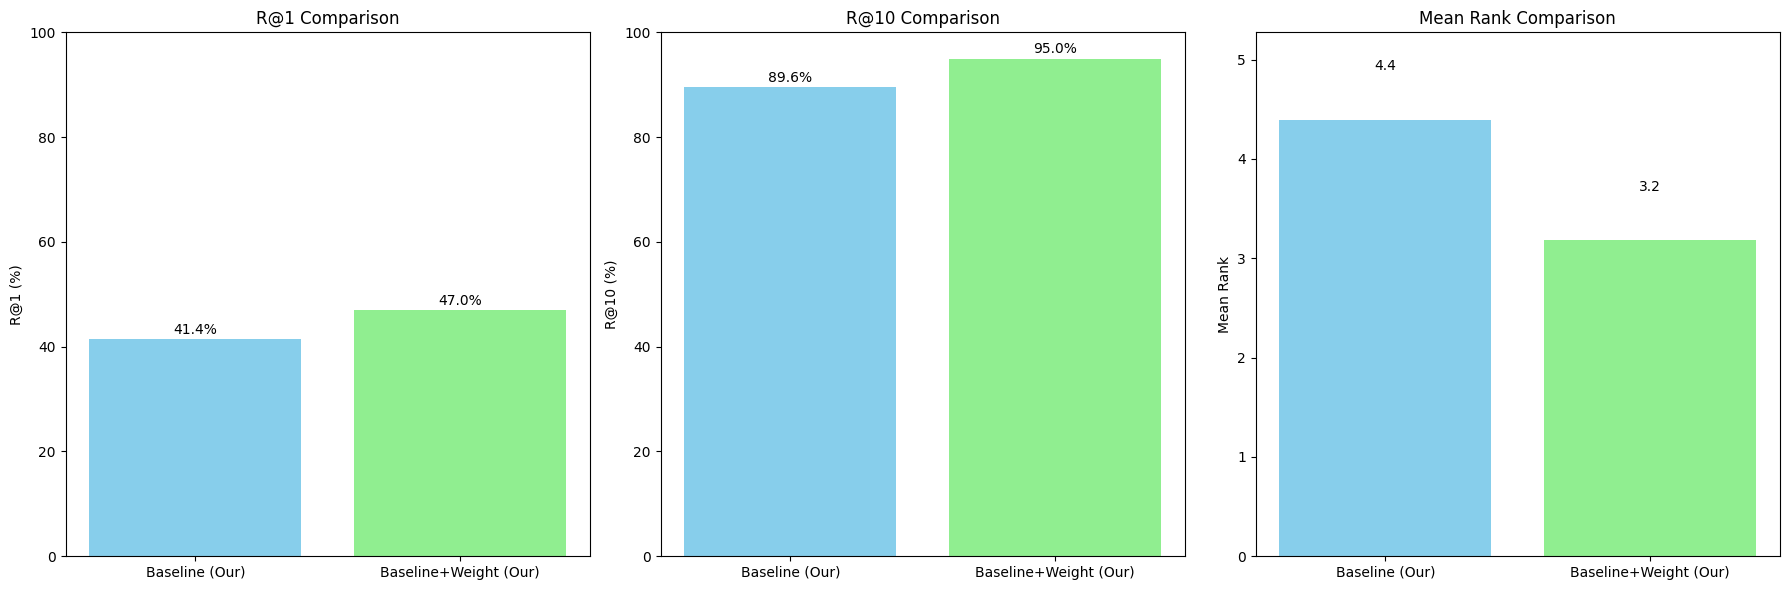

In [ ]:
# Create a DataFrame for easier plotting
import pandas as pd

our_results = {
    'Method': ['Baseline (Our)', 'Baseline+Weight (Our)'],
    'R@1': [recall1_bl, recall1_bw],
    'R@10': [recall10_bl, recall10_bw],
    'Mean r': [mean_rank_bl, mean_rank_bw]
}
our_results_df = pd.DataFrame(our_results)

print("Our Results Summary:")
display(our_results_df)

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# R@1 plot
axes[0].bar(our_results_df['Method'], our_results_df['R@1'], color=['skyblue', 'lightgreen'])
axes[0].set_ylabel('R@1 (%)')
axes[0].set_title('R@1 Comparison')
axes[0].set_ylim(0, 100)
for i, v in enumerate(our_results_df['R@1']):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha='center')

# R@10 plot
axes[1].bar(our_results_df['Method'], our_results_df['R@10'], color=['skyblue', 'lightgreen'])
axes[1].set_ylabel('R@10 (%)')
axes[1].set_title('R@10 Comparison')
axes[1].set_ylim(0, 100)
for i, v in enumerate(our_results_df['R@10']):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha='center')

# Mean r plot
axes[2].bar(our_results_df['Method'], our_results_df['Mean r'], color=['skyblue', 'lightgreen'])
axes[2].set_ylabel('Mean Rank')
axes[2].set_title('Mean Rank Comparison')
# Adjust y-limit based on your mean ranks
max_mean_rank = max(our_results_df['Mean r'])
axes[2].set_ylim(0, max_mean_rank * 1.2)
for i, v in enumerate(our_results_df['Mean r']):
    axes[2].text(i, v + 0.5, f"{v:.1f}", ha='center')


plt.tight_layout()
plt.show()